<a href="https://colab.research.google.com/github/lucnavarro/modelagem-sam/blob/main/sam_segmentacao_pluma.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Segmentação de uma pluma de fumaça com o SAM

Modelagem Computacional - Profa Raquel Lobosco
Aluno: Lucas Ribeiro Navarro - RA: 178181

Neste notebook uso o Segment Anything Model (SAM) para segmentar uma pluma de fumaça em uma imagem, vejo onde ele erra e tento melhorar o resultado com caixa e pontos como prompts.

In [27]:
!pip install -q git+https://github.com/facebookresearch/segment-anything.git opencv-python
!wget -q -nc https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

  Preparing metadata (setup.py) ... done


In [28]:
import numpy as np
import cv2
import torch
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import binary_fill_holes
from google.colab import files
from segment_anything import sam_model_registry, SamPredictor, SamAutomaticMaskGenerator

device = "cuda" if torch.cuda.is_available() else "cpu"
sam = sam_model_registry["vit_b"](checkpoint="sam_vit_b_01ec64.pth")
sam.to(device)
print("rodando em", device)

rodando em cuda


## 1. Imagem escolhida

Imagem usada: foto de uma pluma de cinza vulcânica, com uma montanha no canto inferior esquerdo e uma nuvem branca encostada na base da pluma.

In [29]:
enviado = files.upload()
nome_arquivo = list(enviado.keys())[0]
img = cv2.cvtColor(cv2.imread(nome_arquivo), cv2.COLOR_BGR2RGB)

escala = 1024 / max(img.shape[:2])
if escala < 1:
    img = cv2.resize(img, None, fx=escala, fy=escala, interpolation=cv2.INTER_AREA)
H, W = img.shape[:2]
print(W, "x", H)

Saving preview.webp to preview (2).webp
1024 x 682


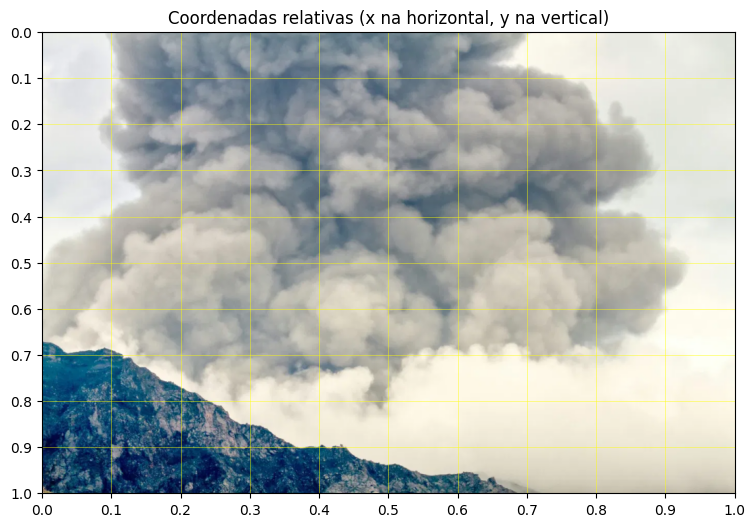

In [30]:
def mostrar_grade(imagem, passo=0.1):
    fig, ax = plt.subplots(figsize=(9, 9 * H / W))
    ax.imshow(imagem)
    marcas = np.arange(0, 1.01, passo)
    ax.set_xticks(marcas * W)
    ax.set_xticklabels([f"{m:.1f}" for m in marcas])
    ax.set_yticks(marcas * H)
    ax.set_yticklabels([f"{m:.1f}" for m in marcas])
    ax.grid(color="yellow", alpha=0.5, lw=0.6)
    ax.set_title("Coordenadas relativas (x na horizontal, y na vertical)")
    plt.show()

mostrar_grade(img)

## 2. Máscara gerada pelo SAM (modo automático)

Primeiro rodo o gerador automático, sem nenhum prompt, só para ver o que o SAM entende como objetos na imagem.

11 máscaras encontradas


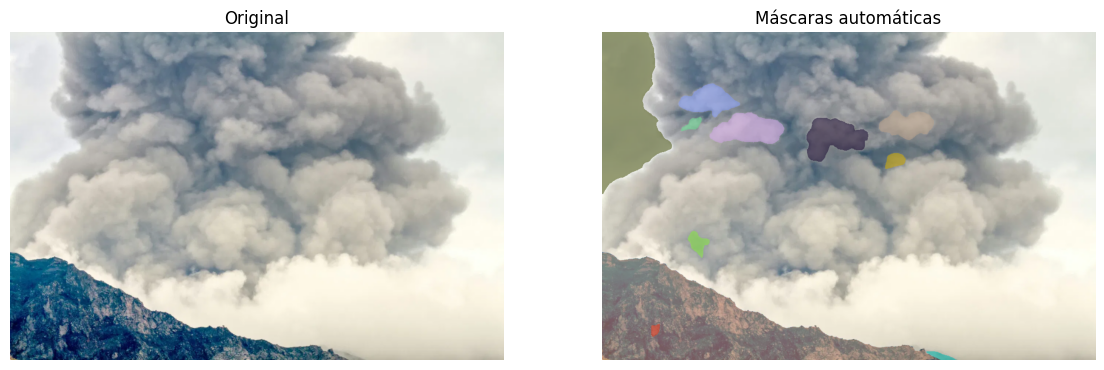

In [31]:
gerador = SamAutomaticMaskGenerator(sam, points_per_side=24, min_mask_region_area=500)
mascaras_auto = gerador.generate(img)
mascaras_auto = sorted(mascaras_auto, key=lambda m: m["area"], reverse=True)
print(len(mascaras_auto), "máscaras encontradas")

rng = np.random.default_rng(0)
cobertura = img.copy().astype(float)
for m in mascaras_auto:
    cor = rng.integers(0, 255, 3)
    cobertura[m["segmentation"]] = 0.45 * cobertura[m["segmentation"]] + 0.55 * cor

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ax[0].imshow(img)
ax[0].set_title("Original")
ax[1].imshow(cobertura.astype(np.uint8))
ax[1].set_title("Máscaras automáticas")
for a in ax:
    a.axis("off")
plt.show()

## 3. Avaliação do resultado automático


A máscara cobre a pluma? Não. O modo automático não gerou uma máscara única para a pluma inteira. Ele pegou só pedaços pequenos e isolados dentro dela, que são algumas “bolhas” de fumaça mais claras ou mais escuras (as manchas azul, rosa, roxa escura, bege, amarela e verde). A maior parte do corpo da pluma ficou sem máscara.

Inclui regiões que não pertencem a ela? Sim. Uma das maiores máscaras cobre o céu do lado esquerdo da imagem, fora da pluma. A montanha embaixo à esquerda também virou uma máscara própria, o que é correto como objeto, mas não é fumaça. Aparecem ainda pequenos fragmentos nas bordas da montanha, na parte de baixo.

Deixa partes da fumaça de fora? Sim, quase toda. A parte de cima, que é mais escura, e a parte de baixo, que é mais clara e parece nuvem, ficaram sem máscara contínua. A nuvem branca encostada na base da pluma também não foi separada dela. Isso mostra que o SAM, sem prompt, não entende a pluma como um único objeto: ela tem muitas texturas e tons diferentes e as bordas são difusas, então ele a divide em pedaços ou ignora.

## 4. Melhorando com prompts

Agora uso o `SamPredictor`, que aceita uma caixa e pontos positivos (dentro da pluma) e negativos (fora dela). As coordenadas são frações da imagem, de 0 a 1, e ajustei olhando a grade da seção 1.

In [32]:
predictor = SamPredictor(sam)
predictor.set_image(img)

def prever(caixa=None, pos=None, neg=None):
    pos = pos or []
    neg = neg or []
    pontos = rotulos = None
    if pos or neg:
        pontos = np.array([[x * W, y * H] for x, y in pos + neg])
        rotulos = np.array([1] * len(pos) + [0] * len(neg))
    box = None
    if caixa is not None:
        box = np.array([caixa[0] * W, caixa[1] * H, caixa[2] * W, caixa[3] * H])
    mascaras, notas, _ = predictor.predict(
        point_coords=pontos, point_labels=rotulos, box=box, multimask_output=True
    )
    melhor = int(np.argmax(notas))
    return mascaras[melhor], float(notas[melhor])

In [33]:
caixa_pluma = (0.02, 0.00, 0.93, 0.78)

configs = {
    "A - só caixa": dict(caixa=caixa_pluma),
    "B - caixa + pontos positivos": dict(
        caixa=caixa_pluma,
        pos=[(0.45, 0.45), (0.70, 0.30), (0.20, 0.55), (0.30, 0.70)],
    ),
    "C - caixa + positivos + negativos": dict(
        caixa=caixa_pluma,
        pos=[(0.45, 0.45), (0.70, 0.30), (0.20, 0.55), (0.30, 0.70)],
        neg=[(0.97, 0.30), (0.02, 0.15), (0.10, 0.90), (0.80, 0.92)],
    ),
}
resultados = {}
for nome, cfg in configs.items():
    resultados[nome] = prever(**cfg)
    print(nome, "- nota do SAM:", round(resultados[nome][1], 3))

A - só caixa - nota do SAM: 0.992
B - caixa + pontos positivos - nota do SAM: 0.979
C - caixa + positivos + negativos - nota do SAM: 0.983


## 5. Comparação lado a lado

Para cada configuração: imagem original com os prompts, máscara binária e máscara sobreposta com contorno.

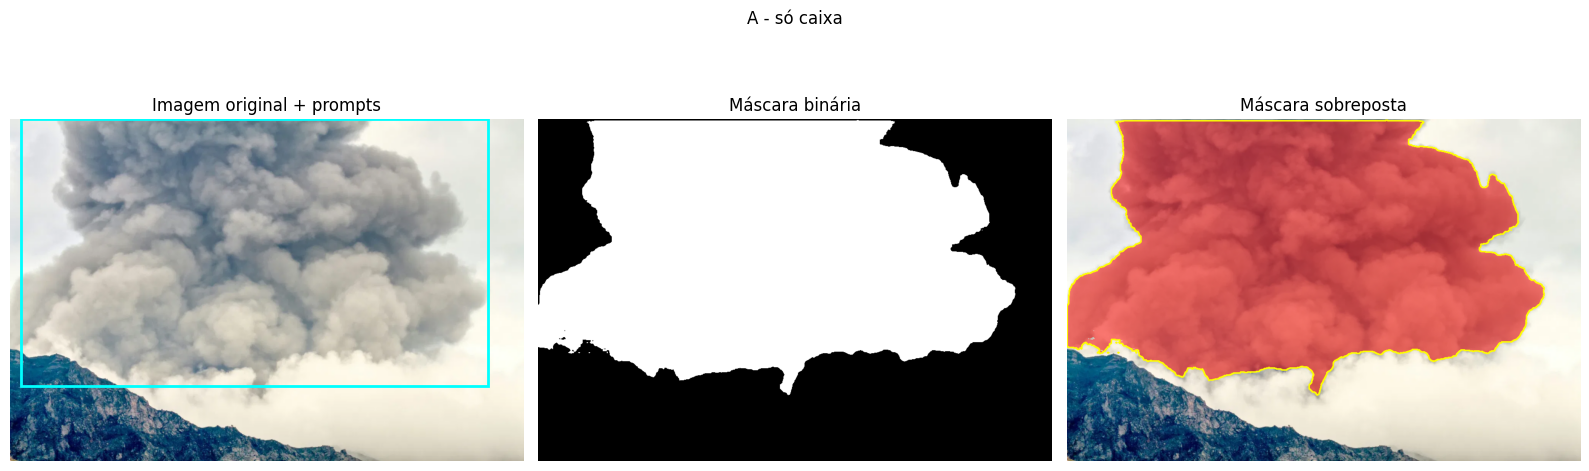

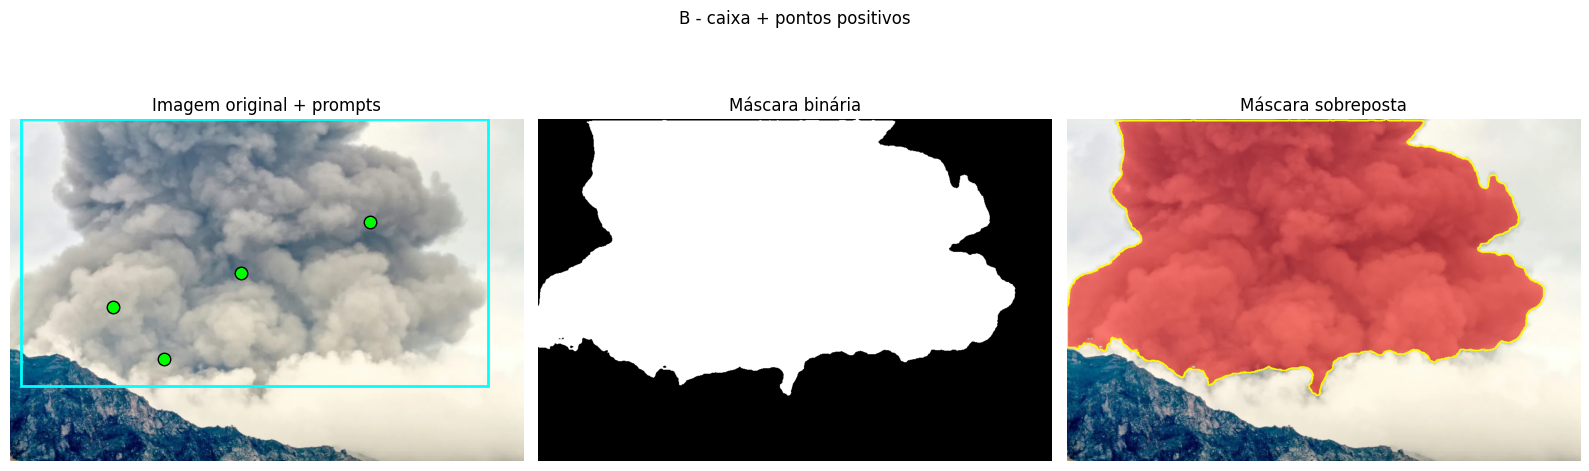

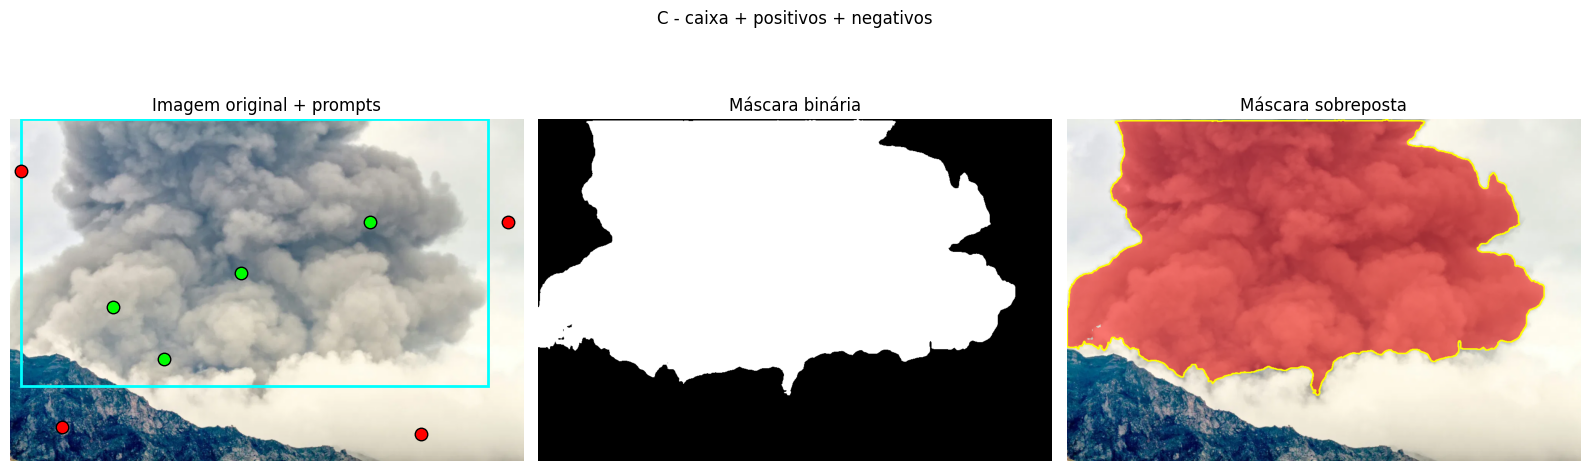

In [34]:
def painel(titulo, mascara, cfg):
    fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))

    ax[0].imshow(img)
    c = cfg.get("caixa")
    if c is not None:
        ax[0].add_patch(plt.Rectangle((c[0] * W, c[1] * H), (c[2] - c[0]) * W, (c[3] - c[1]) * H,
                                      fill=False, ec="cyan", lw=2))
    for x, y in cfg.get("pos", []):
        ax[0].plot(x * W, y * H, "o", color="lime", ms=9, mec="k")
    for x, y in cfg.get("neg", []):
        ax[0].plot(x * W, y * H, "o", color="red", ms=9, mec="k")
    ax[0].set_title("Imagem original + prompts")

    ax[1].imshow(mascara, cmap="gray")
    ax[1].set_title("Máscara binária")

    sobre = img.copy()
    sobre[mascara] = (0.5 * sobre[mascara] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    contornos, _ = cv2.findContours(mascara.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(sobre, contornos, -1, (255, 255, 0), 2)
    ax[2].imshow(sobre)
    ax[2].set_title("Máscara sobreposta")

    for a in ax:
        a.axis("off")
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

for nome, cfg in configs.items():
    painel(nome, resultados[nome][0], cfg)

Comentários:

A (só caixa): A máscara cobre praticamente toda a pluma, inclusive as partes claras da parte de baixo, e separa bem a pluma da nuvem branca e da montanha. A parte de cima fica cortada reto porque a caixa começa no topo da imagem, mas a pluma continua para fora do quadro mesmo. Na versão binária aparecem alguns pontinhos soltos perto da montanha, que a limpeza removeu.

B (caixa + pontos positivos): O resultado ficou praticamente igual ao de A. Os pontos positivos, dentro das partes clara e escura da pluma, não mudaram o contorno de forma visível. A caixa já continha quase toda a informação de que o SAM precisava.

C (caixa + positivos + negativos): Também ficou muito parecido com A e B. Os pontos negativos no céu, na montanha e na nuvem branca da base não precisaram corrigir nada, porque a máscara já não incluía essas regiões. Há uma diferença mínima no lado esquerdo, que pode ser conferida na tabela de IoU. Nesta imagem, a caixa foi o prompt que mais pesou, e os pontos só confirmaram o resultado.

### Limpeza da máscara

Como a apresentação da máscara também conta, aplico abertura e fechamento morfológico, fico só com o maior componente conexo e preencho buracos.

In [35]:
def limpar(mascara, k=9):
    m = mascara.astype(np.uint8)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, kernel)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, kernel)
    n, rotulo, estat, _ = cv2.connectedComponentsWithStats(m)
    if n > 1:
        maior = 1 + int(np.argmax(estat[1:, cv2.CC_STAT_AREA]))
        m = (rotulo == maior).astype(np.uint8)
    return binary_fill_holes(m).astype(bool)

def iou(a, b):
    uniao = (a | b).sum()
    return (a & b).sum() / uniao if uniao else 0.0

escolhida = list(configs)[-1]
limpas = {nome: limpar(r[0]) for nome, r in resultados.items()}
ref = limpas[escolhida]

tabela = pd.DataFrame({
    "nota SAM": [resultados[n][1] for n in configs],
    "área bruta (%)": [100 * resultados[n][0].mean() for n in configs],
    "área limpa (%)": [100 * limpas[n].mean() for n in configs],
    "IoU com a escolhida": [iou(limpas[n], ref) for n in configs],
}, index=list(configs)).round(3)
tabela

,nota SAM,área bruta (%),área limpa (%),IoU com a escolhida
A - só caixa,0.992,54.082,54.318,0.994
B - caixa + pontos positivos,0.979,54.079,54.319,0.996
C - caixa + positivos + negativos,0.983,53.934,54.205,1.000


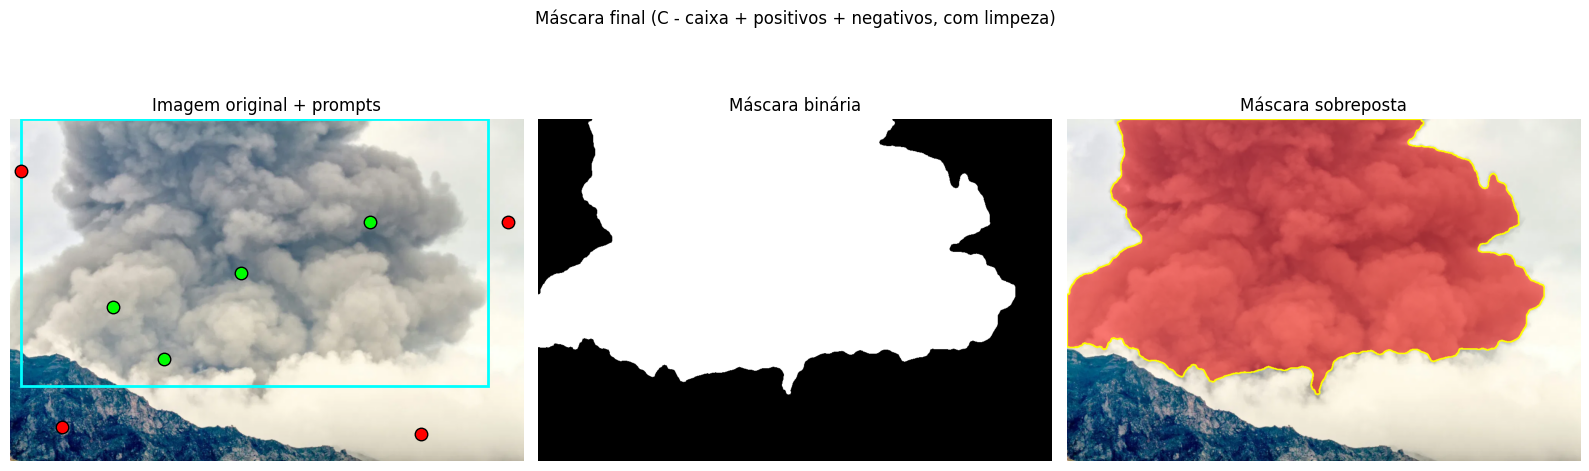

In [36]:
painel("Máscara final (" + escolhida + ", com limpeza)", ref, configs[escolhida])

## 6. O que dificultou a segmentação

Aqui meço na própria imagem o que pode ter atrapalhado: brilho e contraste da fumaça em relação à faixa ao redor, diferença de cor e força do gradiente na borda da máscara.

                            dentro da máscara  faixa ao redor
brilho médio                           163.81          225.17
contraste interno (desvio)              29.22           23.90
saturação média                         22.23           16.92

distância de cor (Lab) entre pluma e entorno: 57.26
gradiente médio na borda: 39.94
gradiente médio na imagem: 20.21
razão borda/imagem: 1.98

fração da região de nuvem dentro da máscara: 0.0
distância de cor (Lab) entre pluma e nuvem: 56.31


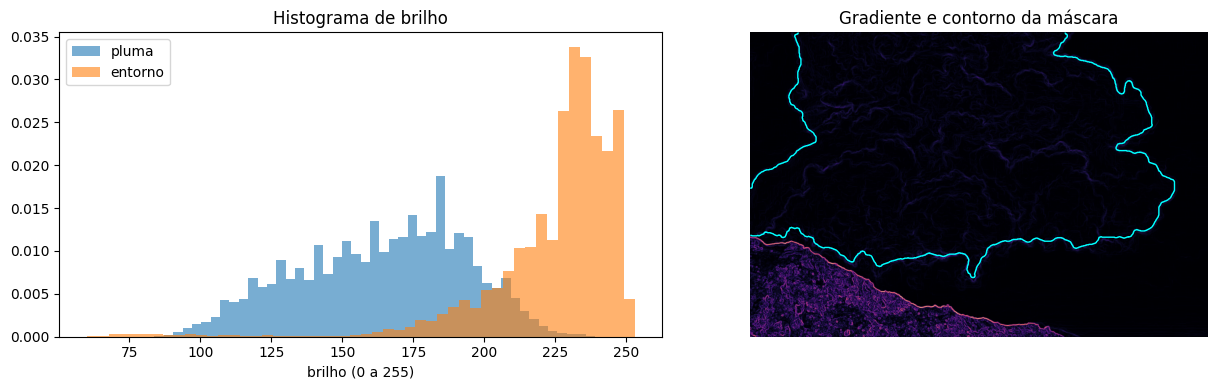

In [37]:
regiao_nuvem = (0.55, 0.82, 0.95, 0.98)

cinza = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(float)
hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(float)
lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB).astype(float)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (41, 41))
anel = cv2.dilate(ref.astype(np.uint8), kernel).astype(bool) & ~ref

def resumo(regiao):
    return {
        "brilho médio": cinza[regiao].mean(),
        "contraste interno (desvio)": cinza[regiao].std(),
        "saturação média": hsv[..., 1][regiao].mean(),
    }

dentro = resumo(ref)
fora = resumo(anel)
comparacao = pd.DataFrame({"dentro da máscara": dentro, "faixa ao redor": fora}).round(2)
print(comparacao)

dist_cor = np.linalg.norm(lab[ref].mean(axis=0) - lab[anel].mean(axis=0))
print("\ndistância de cor (Lab) entre pluma e entorno:", round(dist_cor, 2))

gx = cv2.Sobel(cinza, cv2.CV_64F, 1, 0, ksize=3)
gy = cv2.Sobel(cinza, cv2.CV_64F, 0, 1, ksize=3)
grad = np.hypot(gx, gy)
borda = cv2.morphologyEx(ref.astype(np.uint8), cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
print("gradiente médio na borda:", round(grad[borda].mean(), 2))
print("gradiente médio na imagem:", round(grad.mean(), 2))
print("razão borda/imagem:", round(grad[borda].mean() / grad.mean(), 2))

if regiao_nuvem is not None:
    x0, y0, x1, y1 = regiao_nuvem
    caixa_nuvem = np.zeros((H, W), bool)
    caixa_nuvem[int(y0 * H):int(y1 * H), int(x0 * W):int(x1 * W)] = True
    print("\nfração da região de nuvem dentro da máscara:", round((caixa_nuvem & ref).sum() / caixa_nuvem.sum(), 3))
    d_nuvem = np.linalg.norm(lab[ref].mean(axis=0) - lab[caixa_nuvem].mean(axis=0))
    print("distância de cor (Lab) entre pluma e nuvem:", round(d_nuvem, 2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(cinza[ref], bins=50, alpha=0.6, density=True, label="pluma")
ax[0].hist(cinza[anel], bins=50, alpha=0.6, density=True, label="entorno")
ax[0].set_xlabel("brilho (0 a 255)")
ax[0].legend()
ax[0].set_title("Histograma de brilho")
ax[1].imshow(grad, cmap="magma")
ax[1].contour(ref, levels=[0.5], colors="cyan", linewidths=1)
ax[1].set_title("Gradiente e contorno da máscara")
ax[1].axis("off")
plt.tight_layout()
plt.show()

Análise:

Iluminação: O brilho médio da pluma é 163,8 e o da faixa ao redor é 225,2, uma diferença de cerca de 61 níveis. A pluma é bem mais escura que o céu, mas não de forma uniforme: o topo é escuro e a base, iluminada pelo céu claro, fica bem mais clara. O histograma mostra isso, com a pluma espalhada de 100 a 210 e o entorno concentrado perto de 230 a 250. Essa variação interna de tom faz a mesma pluma parecer partes diferentes, o que explica a divisão em pedaços do modo automático.

Contraste entre fumaça e fundo: A distância de cor (Lab) entre pluma e entorno é de 57,3, então no geral o contraste é alto e ajudou o SAM. O contraste interno da pluma (desvio de 29,2) é maior que o do entorno (23,9), por causa das bolhas claras e escuras. A saturação é baixa nos dois (22,2 e 16,9): tudo é praticamente cinza, e a cor não ajuda a separar fumaça de fundo. O que separa é o brilho. Onde a base da pluma fica clara, o histograma das duas regiões se sobrepõe (entre 190 e 215), e é aí que mora a ambiguidade.

Semelhança com nuvens: A região de nuvem branca que escolhi, na base da imagem à direita, ficou 0,0 dentro da máscara, ou seja, o SAM não a incluiu. A distância de cor entre a pluma e essa nuvem (56,3) é quase igual à distância entre a pluma e o entorno todo (57,3), então em cor média a nuvem é tão diferente da pluma quanto o céu. Isso ajuda a explicar o acerto, mas tem limite: a média da pluma é puxada pelas partes escuras, e as partes claras de baixo se parecem mais com a nuvem do que o número sugere. Além disso, essa caixa fica longe da fronteira, então ela mostra que a nuvem não foi incluída, mas não testa a transição entre as duas.

Bordas da pluma: O gradiente médio na borda da máscara foi 39,9 contra 20,2 na imagem inteira, uma razão de 1,98. Ou seja, a borda é mais nítida que a média da imagem, mas a média é baixa por causa das grandes áreas lisas de céu. A razão ficou perto de 2, e a montanha, com muita textura, tem gradientes ainda maiores. Nas bordas da fumaça, o contorno é irregular e a transição é gradual, então a máscara tem mais incerteza ali do que na separação com a montanha.

## Conclusão

O modo automático do SAM não conseguiu segmentar a pluma. Ele gerou só pedaços pequenos dentro da fumaça, deixou quase todo o corpo dela sem máscara e ainda incluiu uma região do céu e a montanha. Isso aconteceu porque a pluma tem tons muito diferentes (topo escuro e base clara), bordas difusas e muita textura, então o SAM não a trata como um objeto único.

Com prompts o resultado melhorou muito. Usando uma caixa em volta da pluma, a máscara passou a cobrir o corpo todo, inclusive as partes claras da base, e ficou separada da montanha e da nuvem branca. Nesta imagem a caixa foi o prompt que mais pesou. Os pontos positivos e os negativos deixaram as máscaras B e C praticamente iguais à A, porque a caixa já continha quase toda a informação de que o SAM precisava. Os pontos negativos não tiveram o que corrigir, já que a máscara não invadia o céu, a montanha nem a nuvem.

A limpeza morfológica (abertura, fechamento, maior componente e preenchimento de buracos) tirou os pontinhos soltos perto da montanha e deixou o contorno mais liso, sem perder a forma da pluma.

A análise da imagem mostrou que o contraste de brilho entre a pluma e o entorno (163,8 contra 225,2) e a distância de cor (57,3) ajudaram o SAM, enquanto a saturação baixa, o tom variando dentro da pluma e a sobreposição de brilho nas partes claras da base são os pontos mais difíceis. A região de nuvem que testei ficou fora da máscara, mas ela estava longe da fronteira, então a transição entre pluma e nuvem continua sendo a parte mais incerta.

Como limitação, testei só uma imagem e uma caixa bem posicionada. Se a caixa fosse maior ou mal colocada, ou a imagem tivesse a fumaça mais próxima de uma nuvem de cor parecida, os pontos negativos provavelmente fariam mais diferença. Para melhorar em um próximo passo, eu testaria outras imagens, compararia com uma máscara desenhada à mão para calcular o IoU de verdade e usaria o modelo maior (vit_h).

In [38]:
cv2.imwrite("mascara_pluma.png", ref.astype(np.uint8) * 255)
sobre = img.copy()
sobre[ref] = (0.5 * sobre[ref] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
cv2.imwrite("sobreposicao_pluma.png", cv2.cvtColor(sobre, cv2.COLOR_RGB2BGR))
files.download("mascara_pluma.png")
files.download("sobreposicao_pluma.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>